# Xây dựng mô hình giải thuật SVM trên dữ liệu các con thú trong rừng.

## 1. Import thư viện và đọc dataset

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data.csv")

print("Kích thước dataset:", df.shape)
display(df.head(10))


Kích thước dataset: (871, 7)


,AnimalName,symptoms1,symptoms2,symptoms3,symptoms4,symptoms5,Dangerous
0,Dog,Fever,Diarrhea,Vomiting,Weight loss,Dehydration,Yes
1,Dog,Fever,Diarrhea,Coughing,Tiredness,Pains,Yes
2,Dog,Fever,Diarrhea,Coughing,Vomiting,Anorexia,Yes
3,Dog,Fever,Difficulty breathing,Coughing,Lethargy,Sneezing,Yes
4,Dog,Fever,Diarrhea,Coughing,Lethargy,Blue Eye,Yes
5,Dog,Fever,Respiratory distress,Seizuers,Hyperesthesia,Sudden death,Yes
6,Dog,Ulcers,Diarrhea,Poor Appetite,Tarry Stool,Enlarged lymph nodes,Yes
7,Dog,Facial Swelling,Bloody Drool,Foul Breath,Unable To Eat,Lossened Teeth,Yes
8,Dog,Fever,Difficulty breathing,Thrist and urination,Weight loss,Enlarged lymph nodes or Swelling,Yes
9,Dog,Swelling on leg,Painfull,Nasal Discharge,Broken Bones,Nasal Discharge,Yes


## 2. Kiểm tra thông tin dữ liệu

In [2]:

df.info()

print("\nThống kê dữ liệu:")
display(df.describe(include="all"))

print("\nSố giá trị thiếu:")
print(df.isnull().sum())

print("\nSố dòng trùng lặp:")
print(df.duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 871 entries, 0 to 870
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   AnimalName  871 non-null    object
 1   symptoms1   871 non-null    object
 2   symptoms2   871 non-null    object
 3   symptoms3   871 non-null    object
 4   symptoms4   871 non-null    object
 5   symptoms5   871 non-null    object
 6   Dangerous   869 non-null    object
dtypes: object(7)
memory usage: 47.8+ KB

Thống kê dữ liệu:


,AnimalName,symptoms1,symptoms2,symptoms3,symptoms4,symptoms5,Dangerous
count,871,871,871,871,871,871,869
unique,46,232,230,229,217,203,2
top,Buffaloes,Fever,Diarrhea,Coughing,Weight loss,Pains,Yes
freq,129,257,119,95,117,99,849



Số giá trị thiếu:
AnimalName    0
symptoms1     0
symptoms2     0
symptoms3     0
symptoms4     0
symptoms5     0
Dangerous     2
dtype: int64

Số dòng trùng lặp:
28


## 3. Trực quan hóa nhãn mục tiêu

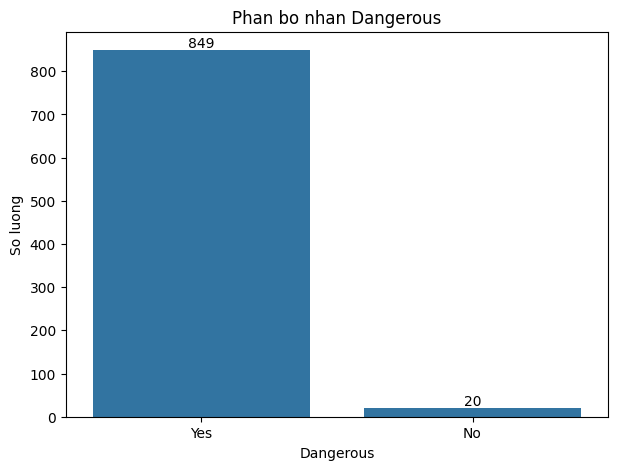

Dangerous
Yes    97.698504
No      2.301496
Name: proportion, dtype: float64


In [3]:

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="Dangerous",
    order=["Yes", "No"]
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Phan bo nhan Dangerous")
plt.xlabel("Dangerous")
plt.ylabel("So luong")
plt.show()

print(df["Dangerous"].value_counts(normalize=True) * 100)


## Nhận xét phân bố nhãn Dangerous
#### Tập dữ liệu ban đầu có 871 mẫu, trong đó 849 mẫu thuộc lớp Yes, 20 mẫu thuộc lớp No và 2 mẫu thiếu nhãn.

#### Trong số các mẫu có nhãn hợp lệ, lớp Yes chiếm 97,70% và lớp No chiếm 2,30%. Điều này cho thấy dữ liệu mất cân bằng nghiêm trọng, có thể khiến mô hình thiên về dự đoán lớp đa số.

#### Do đó, bên cạnh Accuracy, cần sử dụng Precision, Recall, F1-score và Confusion Matrix để đánh giá khả năng phân loại của mô hình.

## 4. Xử lý dữ liệu thiếu, trùng lặp và chuẩn hóa văn bản

In [4]:

df_clean = df.copy()

feature_cols = [
    "AnimalName",
    "symptoms1", "symptoms2", "symptoms3",
    "symptoms4", "symptoms5"
]

for col in feature_cols:
    df_clean[col] = (
        df_clean[col]
        .astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
        .str.lower()
    )

df_clean["Dangerous"] = (
    df_clean["Dangerous"]
    .astype("string")
    .str.strip()
    .str.title()
)

df_clean = df_clean.dropna(subset=["Dangerous"])
df_clean = df_clean.drop_duplicates()
df_clean = df_clean.reset_index(drop=True)

print("Kích thước sau xử lý:", df_clean.shape)
print(df_clean["Dangerous"].value_counts())


Kích thước sau xử lý: (839, 7)
Dangerous
Yes    819
No      20
Name: count, dtype: Int64


### Biểu đồ phân bố các loài động vật

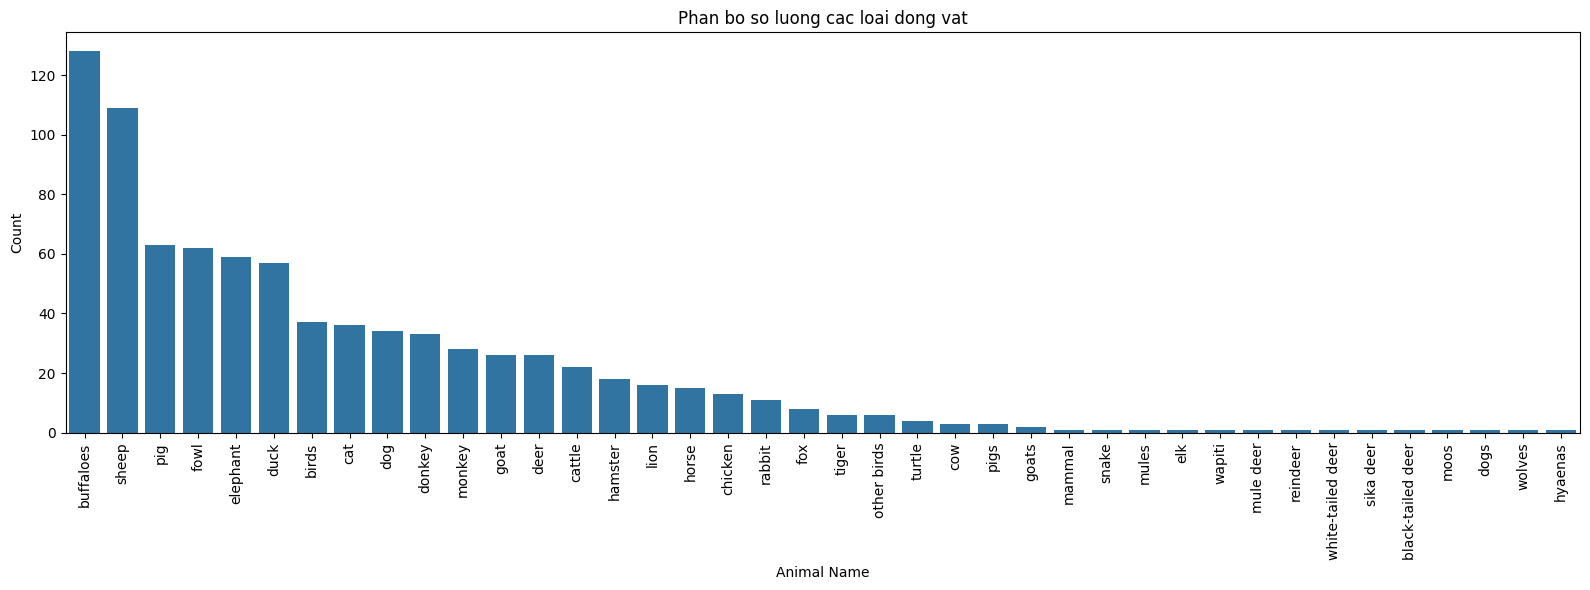

In [5]:

plt.figure(figsize=(16, 6))

sns.countplot(
    data=df_clean,
    x="AnimalName",
    order=df_clean["AnimalName"].value_counts().index
)

plt.xticks(rotation=90)
plt.title("Phan bo so luong cac loai dong vat")
plt.xlabel("Animal Name")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


### Biểu đồ tròn phân bố nhãn Dangerous


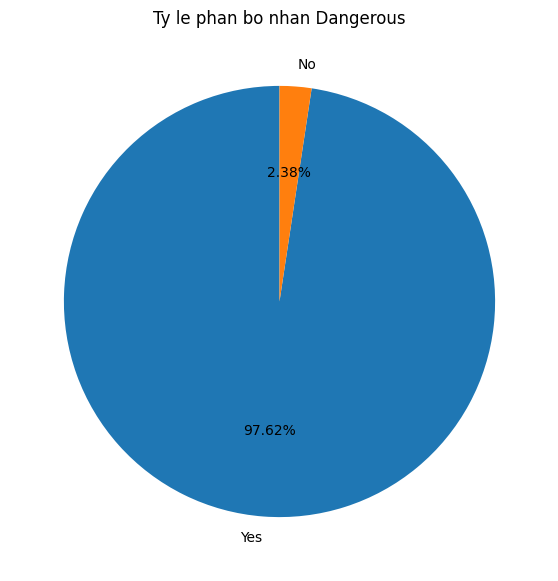

In [6]:

counts = df_clean["Dangerous"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    counts.values,
    labels=counts.index,
    autopct="%1.2f%%",
    startangle=90
)

plt.title("Ty le phan bo nhan Dangerous")
plt.show()


### Kiểm tra các tên động vật và triệu chứng

In [7]:

for col in feature_cols:
    print(f"\n===== {col} =====")
    print("So gia tri khac nhau:",
          df_clean[col].nunique())
    print(df_clean[col].value_counts().head(10))



===== AnimalName =====
So gia tri khac nhau: 40
AnimalName
buffaloes    128
sheep        109
pig           63
fowl          62
elephant      59
duck          57
birds         37
cat           36
dog           34
donkey        33
Name: count, dtype: Int64

===== symptoms1 =====
So gia tri khac nhau: 222
symptoms1
fever               269
loss of appetite     14
sudden death         11
swelling             11
wasting              11
swollen               8
weakness              8
dyspnea               8
emaciation            8
jaundice              8
Name: count, dtype: Int64

===== symptoms2 =====
So gia tri khac nhau: 223
symptoms2
diarrhea                   125
loss of appetite            69
difficulty in breathing     26
depression                  26
chills                      12
stumbling                   11
pneumonia                   10
dyspnea                     10
dullness                    10
dull ness                    9
Name: count, dtype: Int64

===== symptoms3 =====
S

## 5. Tách đặc trưng X và nhãn y

In [8]:

from sklearn.model_selection import train_test_split

X = df_clean.drop(columns=["Dangerous"])
y = df_clean["Dangerous"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nPhân bố nhãn Train:")
print(y_train.value_counts())

print("\nPhân bố nhãn Test:")
print(y_test.value_counts())


X_train: (671, 6)
X_test: (168, 6)

Phân bố nhãn Train:
Dangerous
Yes    655
No      16
Name: count, dtype: Int64

Phân bố nhãn Test:
Dangerous
Yes    164
No       4
Name: count, dtype: Int64


## 6. Tạo tiền xử lý One-Hot Encoding

In [9]:

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            feature_cols
        )
    ]
)

print("Đã tạo bộ tiền xử lý OneHotEncoder.")


Đã tạo bộ tiền xử lý OneHotEncoder.


## 7. Huấn luyện SVM với Kernetl RBF

In [10]:

from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

# Xây dựng mô hình SVM ban đầu
svm_model = Pipeline([
    ("preprocessor", preprocessor),
    ("svm", SVC(kernel="rbf"))
])

# Huấn luyện mô hình
svm_model.fit(X_train, y_train)

# Dự đoán
y_train_pred = svm_model.predict(X_train)
y_pred = svm_model.predict(X_test)

print("Training Accuracy:",
      accuracy_score(y_train, y_train_pred))

print("Testing Accuracy:",
      accuracy_score(y_test, y_pred))


Training Accuracy: 0.9955290611028316
Testing Accuracy: 0.9761904761904762


## 8. Đánh giá mô hình bằng các chỉ số

In [11]:

print("===== DANH GIA SVM BAN DAU =====")

print("Accuracy:",
      accuracy_score(y_test, y_pred))

print("Precision Macro:",
      precision_score(y_test, y_pred,
                      average="macro",
                      zero_division=0))

print("Recall Macro:",
      recall_score(y_test, y_pred,
                   average="macro",
                   zero_division=0))

print("F1-score Macro:",
      f1_score(y_test, y_pred,
               average="macro",
               zero_division=0))

print("Balanced Accuracy:",
      balanced_accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    labels=["No", "Yes"],
    zero_division=0
))


===== DANH GIA SVM BAN DAU =====
Accuracy: 0.9761904761904762
Precision Macro: 0.4880952380952381
Recall Macro: 0.5
F1-score Macro: 0.4939759036144578
Balanced Accuracy: 0.5

Classification Report:
              precision    recall  f1-score   support

          No       0.00      0.00      0.00         4
         Yes       0.98      1.00      0.99       164

    accuracy                           0.98       168
   macro avg       0.49      0.50      0.49       168
weighted avg       0.95      0.98      0.96       168



## 9. Vẽ Confusion Matrix

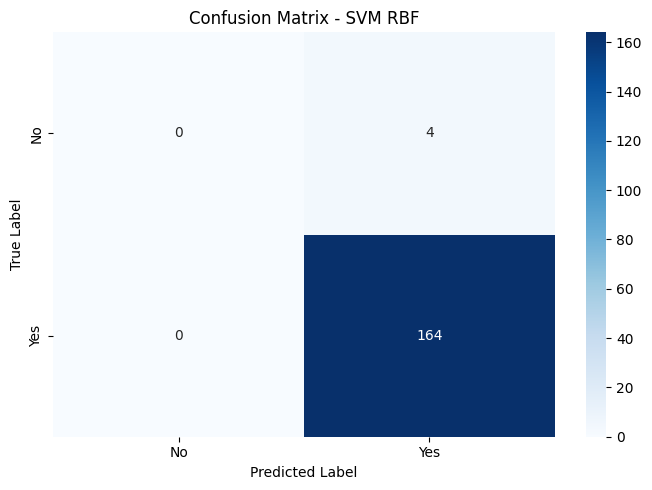

In [12]:

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["No", "Yes"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.title("Confusion Matrix - SVM RBF")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()


## Nhận xét Confusion Matrix trước tinh chỉnh
#### Mô hình SVM ban đầu đạt Accuracy 97,62%, tuy nhiên Confusion Matrix cho thấy mô hình dự đoán tất cả 168 mẫu kiểm tra thuộc lớp Yes.

#### Cụ thể, mô hình nhận diện đúng 164 mẫu Yes nhưng phân loại sai cả 4 mẫu No. Điều này cho thấy mô hình có xu hướng thiên về lớp chiếm đa số.

#### Mặc dù Accuracy tương đối cao, khả năng phân biệt hai lớp của mô hình còn hạn chế, cần tiếp tục cải thiện.

## 10. Huấn luyện và so sánh 4 Kernel

In [13]:

from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score
)

kernels = ["linear", "poly", "rbf", "sigmoid"]

cv_strategy = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

kernel_results = []

for kernel in kernels:
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("svm", SVC(
            kernel=kernel,
            class_weight="balanced"
        ))
    ])

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv_strategy,
        scoring="f1_macro",
        n_jobs=-1
    )

    kernel_results.append({
        "Kernel": kernel,
        "Mean F1": scores.mean(),
        "Std F1": scores.std()
    })

kernel_df = pd.DataFrame(kernel_results)
display(kernel_df.sort_values(
    by="Mean F1", ascending=False
))


,Kernel,Mean F1,Std F1
1,poly,0.878673,0.048379
0,linear,0.864898,0.039711
2,rbf,0.864898,0.039711
3,sigmoid,0.832141,0.056402


## 11. Vẽ biểu đồ so sánh Kernel

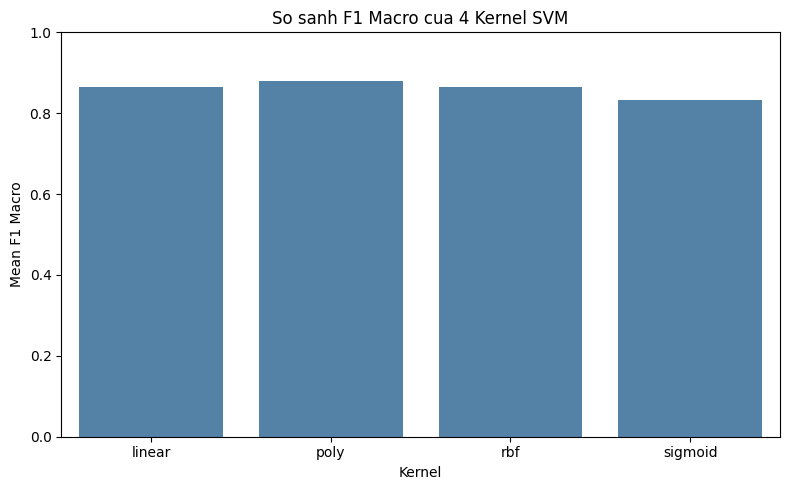

In [14]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=kernel_df,
    x="Kernel",
    y="Mean F1",
    color="steelblue",
    errorbar=None
)

plt.title("So sanh F1 Macro cua 4 Kernel SVM")
plt.xlabel("Kernel")
plt.ylabel("Mean F1 Macro")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


## Nhận xét kết quả so sánh Kernel
#### Kết quả Cross-Validation cho thấy Kernel Poly đạt F1 Macro trung bình cao nhất, khoảng 0,8787, tiếp theo là Linear và RBF với 0,8649, cuối cùng là Sigmoid với 0,8321.

#### Điều này cho thấy việc lựa chọn Kernel có ảnh hưởng đến khả năng phân loại của mô hình. Tuy nhiên, các kết quả này sử dụng tham số mặc định nên chưa thể kết luận Poly là Kernel tối ưu.

#### Vì vậy, cần sử dụng GridSearchCV để tìm tổ hợp Kernel và siêu tham số phù hợp hơn.

## 12. Tìm tham số tốt nhất

In [15]:

from sklearn.model_selection import GridSearchCV

svm_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("svm", SVC(class_weight="balanced"))
])

param_grid = [
    {
        "svm__kernel": ["linear"],
        "svm__C": [0.1, 1, 10]
    },
    {
        "svm__kernel": ["rbf", "poly", "sigmoid"],
        "svm__C": [0.1, 1, 10],
        "svm__gamma": ["scale", "auto"]
    }
]

grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv_strategy,
    n_jobs=-1,
    return_train_score=True
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest CV F1 Macro:")
print(grid_search.best_score_)


Best Parameters:
{'svm__C': 0.1, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}

Best CV F1 Macro:
0.8826386618344395


## 13. Dự đoán bằng mô hình tối ưu

In [16]:

# Lấy mô hình có tham số tốt nhất
best_svm = grid_search.best_estimator_

# Dự đoán trên tập Test
y_pred_tuned = best_svm.predict(X_test)

print("===== SVM SAU TINH CHINH =====")

print("Accuracy:",
      accuracy_score(y_test, y_pred_tuned))

print("Balanced Accuracy:",
      balanced_accuracy_score(y_test, y_pred_tuned))

print("F1 Macro:",
      f1_score(y_test, y_pred_tuned,
               average="macro", zero_division=0))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_tuned,
    labels=["No", "Yes"],
    zero_division=0
))


===== SVM SAU TINH CHINH =====
Accuracy: 1.0
Balanced Accuracy: 1.0
F1 Macro: 1.0

Classification Report:
              precision    recall  f1-score   support

          No       1.00      1.00      1.00         4
         Yes       1.00      1.00      1.00       164

    accuracy                           1.00       168
   macro avg       1.00      1.00      1.00       168
weighted avg       1.00      1.00      1.00       168



## 14. Vẽ Confusion Matrix sau tinh chỉnh

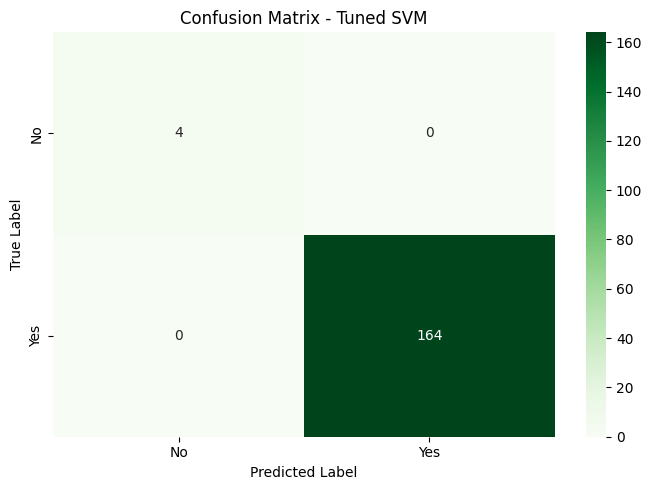

In [17]:

cm_tuned = confusion_matrix(
    y_test,
    y_pred_tuned,
    labels=["No", "Yes"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_tuned,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.title("Confusion Matrix - Tuned SVM")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()


## 15. Tạo bảng so sánh

In [18]:

comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision Macro",
        "Recall Macro",
        "F1 Macro",
        "Balanced Accuracy"
    ],
    "Before Tuning": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred,
                        average="macro",
                        zero_division=0),
        recall_score(y_test, y_pred,
                     average="macro",
                     zero_division=0),
        f1_score(y_test, y_pred,
                 average="macro",
                 zero_division=0),
        balanced_accuracy_score(y_test, y_pred)
    ],
    "After Tuning": [
        accuracy_score(y_test, y_pred_tuned),
        precision_score(y_test, y_pred_tuned,
                        average="macro",
                        zero_division=0),
        recall_score(y_test, y_pred_tuned,
                     average="macro",
                     zero_division=0),
        f1_score(y_test, y_pred_tuned,
                 average="macro",
                 zero_division=0),
        balanced_accuracy_score(y_test, y_pred_tuned)
    ]
})

display(comparison.round(4))


,Metric,Before Tuning,After Tuning
0,Accuracy,0.9762,1.0
1,Precision Macro,0.4881,1.0
2,Recall Macro,0.5000,1.0
3,F1 Macro,0.4940,1.0
4,Balanced Accuracy,0.5000,1.0


## 16. Vẽ biểu đồ so sánh trước và sau

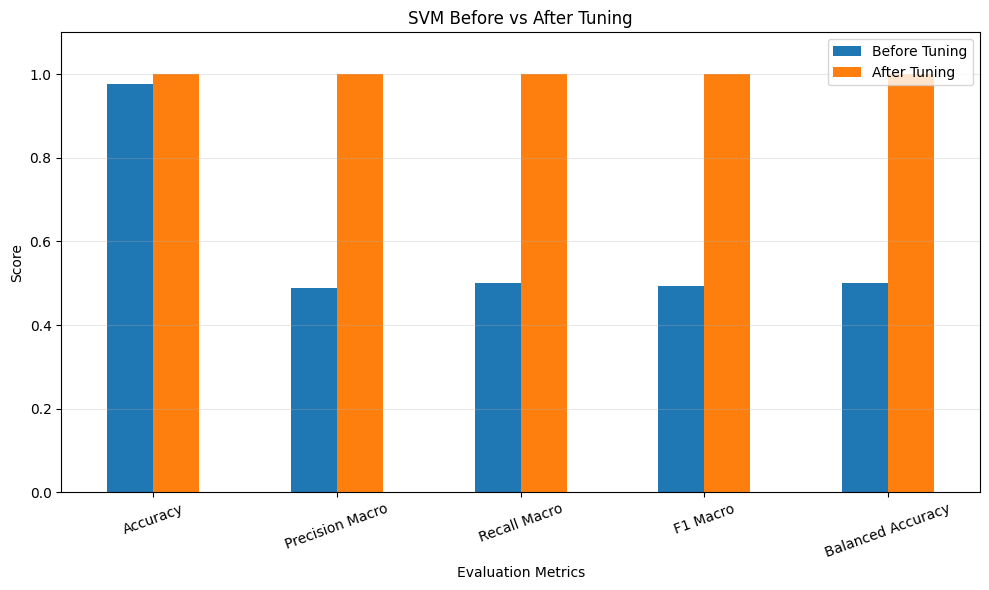

In [19]:

comparison_plot = comparison.set_index("Metric")

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6),
    rot=20
)

plt.title("SVM Before vs After Tuning")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## Nhận xét kết quả sau tinh chỉnh
#### Sau khi sử dụng GridSearchCV, mô hình lựa chọn Kernel RBF với C = 0.1 và gamma = scale, đạt F1 Macro trung bình khoảng 0,8826 trên tập Cross-Validation.

#### Trên tập Test hiện tại, Accuracy tăng từ 97,62% lên 100%, F1 Macro tăng từ 0,4940 lên 1,0000 và Balanced Accuracy tăng từ 0,5000 lên 1,0000.

#### Confusion Matrix sau tinh chỉnh cho thấy mô hình dự đoán đúng toàn bộ 168 mẫu kiểm tra, bao gồm 164 mẫu Yes và 4 mẫu No.

#### Kết quả cho thấy hiệu suất trên tập Test đã được cải thiện rõ rệt. Tuy nhiên, cần tiếp tục kiểm tra khả năng tổng quát hóa trên dữ liệu mới.

# 17. Hạn chế của mô hình và hướng cải thiện
##      1. Hạn chế

#### Mất cân bằng dữ liệu: Tập dữ liệu sau làm sạch có 819 mẫu Yes và chỉ 20 mẫu No. Sự chênh lệch này có thể khiến mô hình thiên về lớp đa số và gặp khó khăn trong việc nhận diện lớp thiểu số.

#### Số lượng mẫu kiểm tra hạn chế: Tập Test chỉ có 4 mẫu No. Mặc dù mô hình sau tinh chỉnh đạt Accuracy 100%, kết quả này chưa đủ để khẳng định mô hình có thể dự đoán chính xác trên mọi dữ liệu mới.

#### Nguy cơ đánh giá quá lạc quan: Các mẫu có tên động vật và triệu chứng tương tự nhau có thể xuất hiện trong cả tập Train và Test. Điều này có thể làm cho bài toán kiểm tra trở nên dễ hơn so với dữ liệu hoàn toàn mới.

##      2. Hướng cải thiện

#### Thu thập thêm dữ liệu, đặc biệt là các mẫu thuộc lớp No, nhằm cải thiện mức độ cân bằng giữa hai lớp.

#### Tiếp tục sử dụng Stratified Cross-Validation để đánh giá tính ổn định của mô hình trên nhiều tập dữ liệu.

#### Thử nghiệm thêm các giá trị C, gamma và các phương pháp xử lý mất cân bằng phù hợp.

#### Đánh giá mô hình trên tập dữ liệu độc lập để kiểm tra khả năng tổng quát hóa.

#### Xem xét chia dữ liệu theo nhóm động vật hoặc nhóm trường hợp tương tự nếu mục tiêu là dự đoán trên các nhóm chưa xuất hiện khi huấn luyện.

##      3. Kết luận

#### Thông qua bài thực hành, mô hình SVM đã được xây dựng, huấn luyện và tối ưu hóa bằng GridSearchCV.

#### Kết quả cho thấy việc lựa chọn Kernel và điều chỉnh siêu tham số giúp cải thiện đáng kể hiệu suất phân loại trên tập dữ liệu kiểm tra.

#### Tuy nhiên, do dữ liệu mất cân bằng và số lượng mẫu thuộc lớp thiểu số còn hạn chế, cần đánh giá thêm trên các tập dữ liệu khác trước khi áp dụng mô hình vào thực tế.